# Auto-label the remaining photos
1. Convert the 809 hand boxes (X-AnyLabeling JSON) → YOLO format, one class `brick`.
2. Train a small YOLO11 detector on them (15% held out).
3. Predict boxes on the other ~5700 photos.
4. Accept confident ones; send the rest to `labeling/review/` for fixing in X-AnyLabeling.
5. Write `data/boxes.csv`: every box for every photo (manual + auto), with its element ID.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, json, glob, os, random, shutil
from collections import Counter, defaultdict
import cv2, numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

rows = list(csv.DictReader(open('data/labels.csv')))
by_key = {(r['element_id'], os.path.basename(r['path'])): r for r in rows}   # (element, IMG_xxxx.JPG) -> row
WINDOW, FRAME = '4541873', '4530590'   # window photos hold 2 pieces: gold doors inside white frame
YOLO_DIR = 'yolo_box'
CONF_OK = 0.6   # min confidence to auto-accept

## 1. Hand boxes → YOLO format

In [2]:
def box(s):
    p = np.array(s['points']); return [*p.min(0), *p.max(0)]

manual = {}   # original path -> list of (element_id, x0, y0, x1, y1)
for f in glob.glob('labeling/labels/*.json'):
    j = json.load(open(f))
    e, img = os.path.basename(f)[:-5].split('_', 1)
    r = by_key[(e, img + '.JPG')]
    manual[r['path']] = [(e if s['label'] == 'brick' else s['label'], *box(s)) for s in j['shapes']]

shutil.rmtree(YOLO_DIR, ignore_errors=True)
paths = sorted(manual); random.Random(0).shuffle(paths)
n_val = int(0.15 * len(paths))
for i, p in enumerate(paths):
    split = 'val' if i < n_val else 'train'
    os.makedirs(f'{YOLO_DIR}/{split}/images', exist_ok=True); os.makedirs(f'{YOLO_DIR}/{split}/labels', exist_ok=True)
    stem = os.path.basename(os.path.dirname(p)) + '_' + os.path.basename(p)[:-4]
    os.link(p, f'{YOLO_DIR}/{split}/images/{stem}.JPG')
    W, H = 4032, 3024
    assert cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_8).shape[:2] == (H // 8, W // 8), p   # EXIF stripped → all landscape
    with open(f'{YOLO_DIR}/{split}/labels/{stem}.txt', 'w') as fh:
        for _, x0, y0, x1, y1 in manual[p]:
            fh.write(f'0 {(x0+x1)/2/W:.6f} {(y0+y1)/2/H:.6f} {(x1-x0)/W:.6f} {(y1-y0)/H:.6f}\n')

open(f'{YOLO_DIR}/data.yaml', 'w').write(f'path: {os.path.abspath(YOLO_DIR)}\ntrain: train/images\nval: val/images\nnames:\n  0: brick\n')
print(len(paths) - n_val, 'train,', n_val, 'val')

688 train, 121 val


## 2. Train
YOLO11s at 1024 px: pieces are small in a 4032 px frame, 640 would shrink small bricks to ~15 px.

In [3]:
BEST = 'runs/detect/runs/box/weights/best.pt'   # ultralytics nests relative project dirs under runs/detect/
if not os.path.exists(BEST):   # training takes ~20 min; skip if already done
    YOLO('yolo11s.pt').train(data=f'{YOLO_DIR}/data.yaml', imgsz=1024, epochs=60, batch=8, cache='ram',
                             project='runs', name='box', exist_ok=True, plots=True, verbose=False)
best = YOLO(BEST)
m = best.val(data=f'{YOLO_DIR}/data.yaml', imgsz=1024, verbose=False)
print(f'val mAP50 {m.box.map50:.3f}  mAP50-95 {m.box.map:.3f}  P {m.box.mp:.3f}  R {m.box.mr:.3f}')

Ultralytics 8.4.215 🚀 Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060, 11907MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11326.2±2522.8 MB/s, size: 1852.7 KB)
val: Scanning /home/denkata/Desktop/Lego Fusion Battle Towers Model/yolo_box/val/labels... 121 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 121/121 1.9Kit/s 0.1s
val: New cache created: /home/denkata/Desktop/Lego Fusion Battle Towers Model/yolo_box/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.7s0.3ss
                   all        121        125      0.999          1      0.995       0.69
Speed: 2.8ms preprocess, 13.5ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /home/denkata/Desktop/Lego Fusion Battle Towers Model/runs/detect/val-4
val mAP50 0.995  mAP50-95 0.690  P 0.999  R 1.000


## 3. Predict on the rest
Expected boxes: 2 for window photos, else 1. Wrong count or low confidence → review.

In [4]:
todo = [r for r in rows if r['path'] not in manual]
auto, review = {}, []
def predict_chunks(rs, n=16):   # one big list OOM-kills the kernel; chunks keep memory flat
    for i in range(0, len(rs), n):
        for r, res in zip(rs[i:i+n], best.predict([r['path'] for r in rs[i:i+n]], imgsz=1024, conf=0.1, verbose=False)):
            yield r, res.boxes.cpu()

for r, b in predict_chunks(todo):
    order = b.conf.argsort(descending=True)
    xyxy, conf = b.xyxy[order].tolist(), b.conf[order].tolist()
    want = 2 if r['element_id'] == WINDOW else 1
    xyxy, conf = xyxy[:want], conf[:want]
    if want == 2 and len(xyxy) == 2:   # bigger box = frame, smaller = doors
        xyxy.sort(key=lambda q: -(q[2]-q[0])*(q[3]-q[1]))
        labels = [FRAME, WINDOW]
    else:
        labels = [r['element_id']] * len(xyxy)
    auto[r['path']] = [(l, *q, c) for l, q, c in zip(labels, xyxy, conf)]
    if len(xyxy) != want or min(conf, default=0) < CONF_OK or len(b) > want:   # extra boxes above conf=0.1 also suspicious
        review.append(r)
print(len(auto), 'predicted,', len(review), 'flagged for review')
print('flagged per element:', Counter(r['element_id'] for r in review).most_common(10))

5683 predicted, 209 flagged for review
flagged per element: [('4541873', 180), ('4211494', 8), ('4121972', 4), ('4270470', 2), ('6106189', 2), ('4211199', 2), ('4211222', 1), ('4530590', 1), ('4211394', 1), ('4211389', 1)]


## 4. Look at accepted and flagged samples

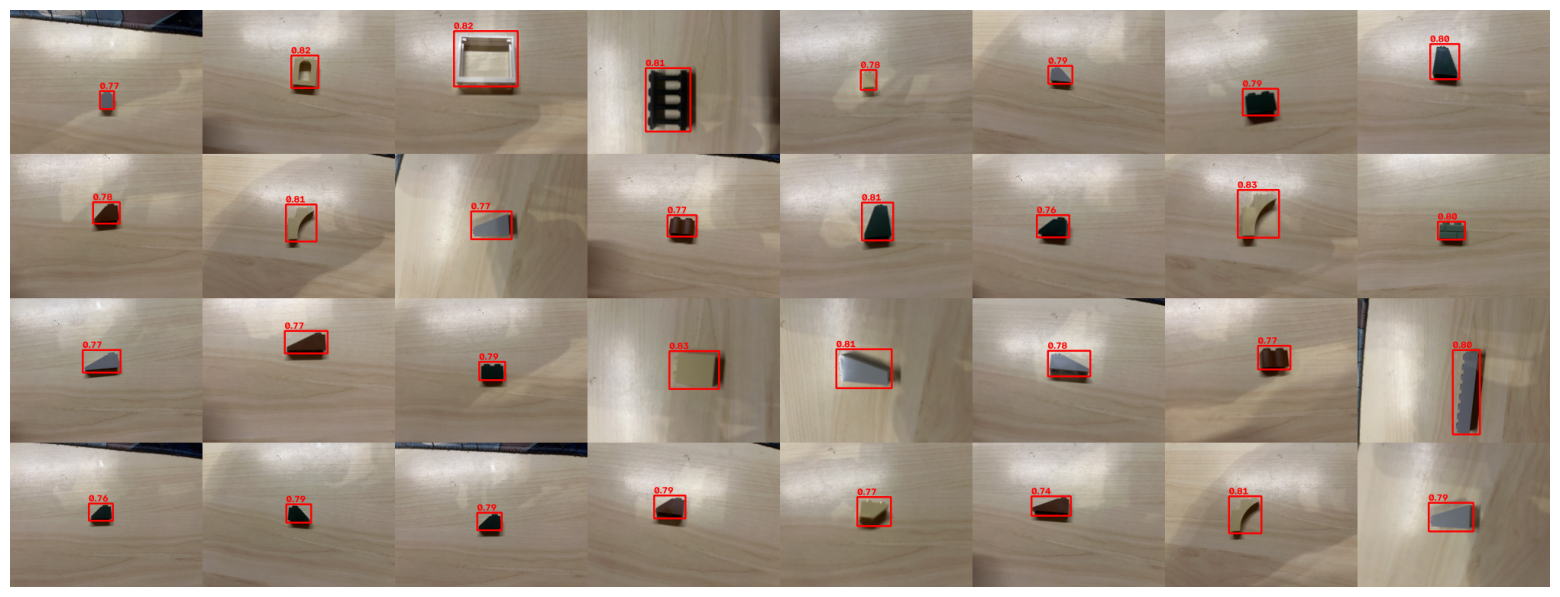

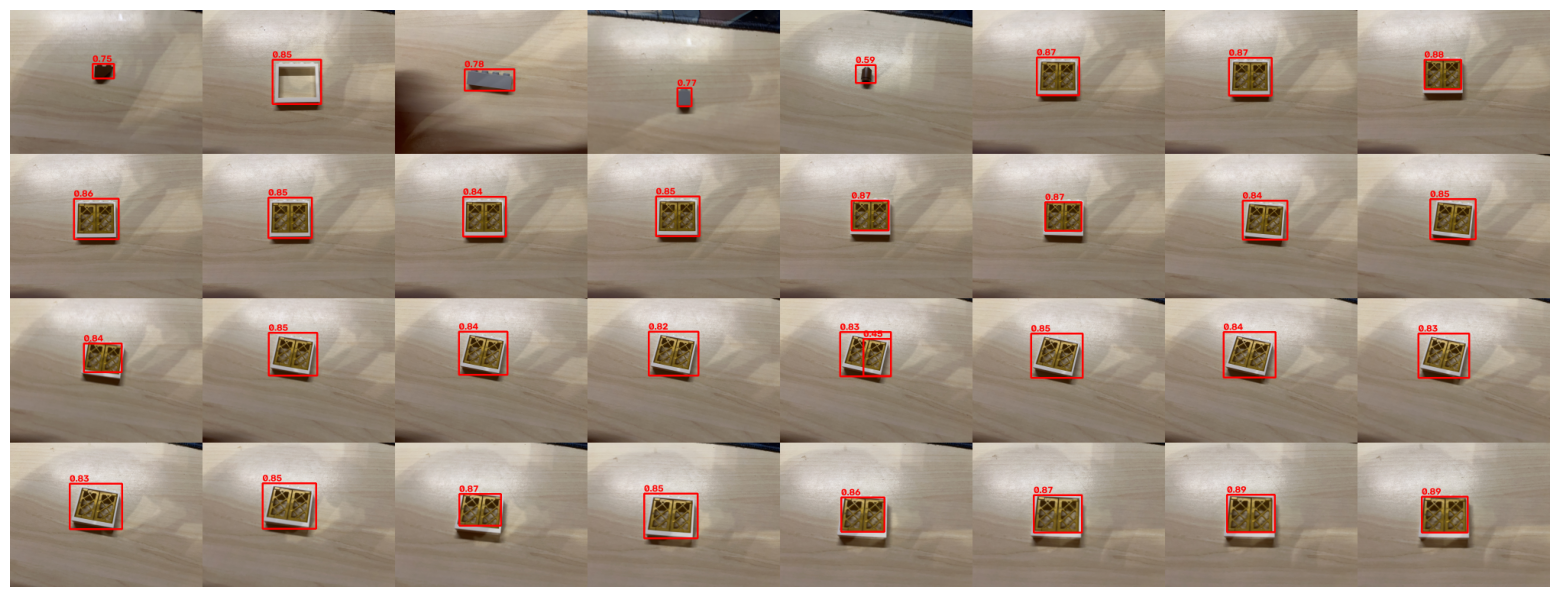

In [5]:
def show(paths, boxes, cols=8, n=32):
    tiles = []
    for p in paths[:n]:
        im = cv2.imread(p, cv2.IMREAD_REDUCED_COLOR_8)
        for l, x0, y0, x1, y1, *c in boxes[p]:
            cv2.rectangle(im, (int(x0/8), int(y0/8)), (int(x1/8), int(y1/8)), (0, 0, 255), 3)
            if c: cv2.putText(im, f'{c[0]:.2f}', (int(x0/8), int(y0/8) - 5), 0, 0.8, (0, 0, 255), 2)
        tiles.append(cv2.resize(im, (252, 189)))
    if not tiles: return print('nothing to show')
    tiles += [np.zeros_like(tiles[0])] * (-len(tiles) % cols)
    sheet = np.vstack([np.hstack(tiles[i:i+cols]) for i in range(0, len(tiles), cols)])
    plt.figure(figsize=(20, 20 * sheet.shape[0] / sheet.shape[1])); plt.imshow(sheet[..., ::-1]); plt.axis('off'); plt.show()

flagged = {r['path'] for r in review}
ok = [p for p in auto if p not in flagged]
show(random.Random(1).sample(ok, min(32, len(ok))), auto)   # accepted
show([r['path'] for r in review], auto)                      # flagged

## 5. Export flagged photos for review in X-AnyLabeling
Open with `scripts/review.sh`. Fix the boxes, then re-run the cell below it to merge.

In [6]:
R = 'labeling/review'
shutil.rmtree(R, ignore_errors=True); os.makedirs(f'{R}/images'); os.makedirs(f'{R}/labels')
for r in review:
    name = f"{r['element_id']}_{os.path.basename(r['path'])[:-4]}"
    os.link(r['path'], f'{R}/images/{name}.JPG')
    shapes = [{'label': 'brick' if l == r['element_id'] else l, 'points': [[x0, y0], [x1, y0], [x1, y1], [x0, y1]],
               'shape_type': 'rectangle', 'flags': {}, 'group_id': None, 'description': f'auto {c:.2f}'}
              for l, x0, y0, x1, y1, c in auto[r['path']]]
    json.dump({'version': '4.3.3', 'flags': {}, 'shapes': shapes, 'imagePath': f'../images/{name}.JPG',
               'imageData': None, 'imageHeight': 3024, 'imageWidth': 4032}, open(f'{R}/labels/{name}.json', 'w'), indent=2)
print(len(review), 'photos in', R)

209 photos in labeling/review


## 6. Write `data/boxes.csv` (run again after reviewing)
Reviewed JSONs override the auto boxes.

In [ ]:
final = {p: [(l, x0, y0, x1, y1, 'manual') for l, x0, y0, x1, y1 in b] for p, b in manual.items()}
for p, b in auto.items():
    final[p] = [(l, x0, y0, x1, y1, f'auto {c:.2f}') for l, x0, y0, x1, y1, c in b]
for f in glob.glob('labeling/review/labels/*.json'):
    e, img = os.path.basename(f)[:-5].split('_', 1)
    p = by_key[(e, img + '.JPG')]['path']
    final[p] = [(e if s['label'] == 'brick' else s['label'], *box(s), 'reviewed') for s in json.load(open(f))['shapes']]

# shortcut: window frame + doors merged into one assembly box; split again if separate frame/door detection is needed
for p, b in final.items():
    if '/60607_' in p and b:
        final[p] = [(WINDOW, min(q[1] for q in b), min(q[2] for q in b), max(q[3] for q in b), max(q[4] for q in b), b[0][5])]

with open('data/boxes.csv', 'w', newline='') as fh:
    w = csv.writer(fh); w.writerow(['path', 'element_id', 'x0', 'y0', 'x1', 'y1', 'source'])
    for p in sorted(final):
        for l, x0, y0, x1, y1, src in final[p]:
            w.writerow([p, l, round(x0, 1), round(y0, 1), round(x1, 1), round(y1, 1), src])
print(Counter(src.split()[0] for b in final.values() for *_, src in b), '| photos without box:', sum(not b for b in final.values()))